# scikit-learn interface

`mboostrs.sklearn` wraps the boosting models as scikit-learn estimators, so they
work in pipelines, `GridSearchCV` and `cross_val_score`. Estimators take NumPy
`X`/`y` (no formula needed for the GLM variants) and expose `fit`/`predict`/`score`.

```{list-table}
:header-rows: 1
* - Estimator
  - Wraps
* - `GLMBoostRegressor`, `GLMBoostClassifier`
  - `glmboost` (linear terms over the columns of `X`)
* - `GAMBoostRegressor`, `GAMBoostClassifier`
  - `gamboost` (smooth `bbs` term per column, controlled by `df`)
```

In [1]:
import numpy as np
from sklearn.model_selection import cross_val_score, GridSearchCV
from mboostrs.sklearn import GLMBoostRegressor, GAMBoostRegressor

rng = np.random.default_rng(0)
n, p = 300, 10
X = rng.normal(size=(n, p))
y = 2 * X[:, 0] - 1.5 * X[:, 1] + np.sin(2 * X[:, 2]) + rng.normal(scale=.4, size=n)

## Regressors

In [2]:
reg = GLMBoostRegressor(mstop=200, nu=0.1).fit(X, y)
print("R^2:", round(float(reg.score(X, y)), 3))

R^2: 0.926


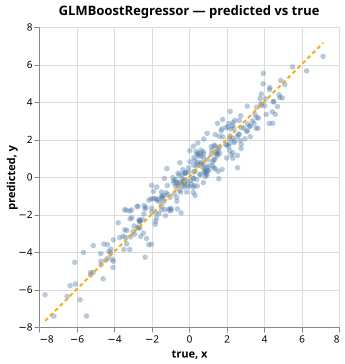

In [3]:
import polars as pl
import altair as alt
y_hat = reg.predict(X)
alt.Chart(pl.DataFrame({"true": y, "predicted": y_hat})).mark_circle(opacity=0.4).encode(
    x="true", y="predicted"
).properties(title="GLMBoostRegressor — predicted vs true") + alt.Chart(
    pl.DataFrame({"x": [y.min(), y.max()], "y": [y.min(), y.max()]})
).mark_line(color="orange", strokeDash=[4, 3]).encode(x="x", y="y")

## Cross-validation and grid search

In [4]:
gam = GAMBoostRegressor(df=4, mstop=200, nu=0.1)
scores = cross_val_score(gam, X, y, cv=5, scoring="r2")
print("5-fold R^2:", np.round(scores, 3))

5-fold R^2: [0.966 0.962 0.968 0.976 0.975]


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 4 learner(s) are asked to predict outside the range they were fitted on. bbs(f8), covariate f8: 2 below -2.92809 (worst 0.17 training ranges out); bbs(f3), covariate f3: 1 below -2.995 (worst 0.14 training ranges out); bbs(f4), covariate f4: 1 below -2.37893 (worst 0.11 training ranges out); bbs(f9), covariate f9: 1 above 2.47244 (worst 0.1 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.17 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 2 learner(s) are asked to predict outside t

In [5]:
grid = GridSearchCV(
    GLMBoostRegressor(nu=0.1),
    param_grid={"mstop": [50, 100, 200, 400]},
    cv=5, scoring="neg_mean_squared_error",
)
grid.fit(X, y)
print("best mstop:", grid.best_params_["mstop"])

best mstop: 100


## Binary classifier

The `*Classifier` variants wrap a Binomial `glmboost` / `gamboost`:

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from mboostrs.sklearn import GAMBoostClassifier

y_clf = (y > 0).astype(float)
X_tr, X_te, y_tr, y_te = train_test_split(X, y_clf, test_size=0.3, random_state=0)
clf = GAMBoostClassifier(df=4, mstop=200, nu=0.1).fit(X_tr, y_tr)
print(f"Accuracy:  {accuracy_score(y_te, clf.predict(X_te)):.3f}")
print(f"ROC AUC:   {roc_auc_score(y_te, clf.predict_proba(X_te)[:, 1]):.3f}")

Accuracy:  0.889
ROC AUC:   0.979


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 2 learner(s) are asked to predict outside the range they were fitted on. bbs(f5), covariate f5: 2 below -2.13261 and 1 above 2.59966 (worst 0.11 training ranges out); bbs(f0), covariate f0: 1 below -3.01145 and 2 above 2.36916 (worst 0.072 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.11 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 2 learner(s) are asked to predict outside the range they were fitted on. bbs(f5), covariate f5: 2 below -2.13261 and 1 above 2.59966 (worst 0.11 t

In [7]:
import polars as pl
import altair as alt
probs = clf.predict_proba(X_te)[:, 1]
df_roc = pl.DataFrame({"score": probs, "label": y_te})
alt.Chart(df_roc).mark_tick(height=8, thickness=2, opacity=0.5).encode(
    x="score:Q", color="label:N"
).properties(title="Predicted probabilities by true class")

# Also a formula-based GAM variant (columns auto-named f0, f1, ...)
gam_clf = GAMBoostClassifier(formula="y ~ bbs(f0, df=5) + bbs(f1, df=3)", mstop=200, nu=0.1).fit(X_tr, y_tr)
print(f"Formula GAM accuracy: {accuracy_score(y_te, gam_clf.predict(X_te)):.3f}")

Formula GAM accuracy: 0.889


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 2 learner(s) are asked to predict outside the range they were fitted on. bbs(f5), covariate f5: 2 below -2.13261 and 1 above 2.59966 (worst 0.11 training ranges out); bbs(f0), covariate f0: 1 below -3.01145 and 2 above 2.36916 (worst 0.072 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.11 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(f0), covariate f0: 1 below -3.01145 and 2 above 2.36916 (worst 0.072 

## Pipeline with ColumnTransformer

Combine with sklearn preprocessing for mixed-type data:

In [8]:
import polars as pl
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

age = rng.uniform(18, 80, n)
income = rng.lognormal(10, 0.5, n)
# Build the response from these columns. Reusing `y` from the first cell would
# pair it with three freshly drawn predictors it has no relationship to, and
# both sections below would score ~0 while the plumbing they demonstrate was
# working perfectly.
df = pl.DataFrame({
    "age": age,
    "income": income,
    "education": rng.choice(["low", "mid", "high"], n),
    "y": 0.05 * age + 2.0 * np.log(income) + rng.normal(0, 1.0, n),
})
ct = ColumnTransformer([
    ("num", StandardScaler(), ["age", "income"]),
])
pipe = Pipeline([
    ("preprocess", ct),
    ("gb", GLMBoostRegressor(mstop=200, nu=0.1)),
])
pipe.fit(df[["age", "income", "education"]], df["y"])
print("Pipeline R^2:", round(float(pipe.score(df[["age", "income", "education"]], df["y"])), 3))

Pipeline R^2: 0.615


## Formula-based GAM in a pipeline

Pass a full mboostrs `formula=` for per-term control (mixed `bols`/`bbs`/
`btree`, per-feature `df`, `by=` interactions):

In [9]:
gam_f = GAMBoostRegressor(
    formula="y ~ bols(age) + bbs(income, df=5)",
    mstop=200, nu=0.1,
)
gam_f.fit(df[["age", "income"]], df["y"])
print("Formula GAM R^2:", round(float(gam_f.score(df[["age", "income"]], df["y"])), 3))

Formula GAM R^2: 0.651


## Estimator-check compliance

sklearn ships
`estimator_checks_generator`, the same battery `check_estimator` runs, which
probes `NotFittedError` behavior, parameter round-tripping, `n_features_in_`
consistency, and dozens of other conventions. Run it against all four
estimators:

In [10]:
from sklearn.utils.estimator_checks import estimator_checks_generator
from mboostrs.sklearn import GLMBoostClassifier, GAMBoostClassifier

for est in [GLMBoostRegressor(), GAMBoostRegressor(), GLMBoostClassifier(), GAMBoostClassifier()]:
    total, failed = 0, []
    for est_i, check in estimator_checks_generator(est, legacy=True):
        total += 1
        try:
            check(est_i)
        except Exception as e:
            failed.append((check.func.__name__, type(e).__name__))
    print(f"{type(est).__name__:20s} {total - len(failed)}/{total} checks passed"
          + (f"  (skipped: {failed})" if failed else ""))


GLMBoostRegressor    57/59 checks passed  (skipped: [('check_sample_weight_equivalence_on_dense_data', 'AssertionError'), ('check_array_api_input', 'SkipTest')])


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 15 learner(s) are asked to predict outside the range they were fitted on. bbs(f0), covariate f0: 2 below 0.341066 (worst 0.45 training ranges out); bbs(f14), covariate f14: 1 below 0.0841068 and 3 above 0.706857 (worst 0.38 training ranges out); bbs(f8), covariate f8: 2 below 0.0745506 and 2 above 0.750871 (worst 0.31 training ranges out); bbs(f19), covariate f19: 1 below 0.0813488 and 1 above 0.779876 (worst 0.27 training ranges out); bbs(f11), covariate f11: 2 below 0.198716 (worst 0.23 training ranges out); bbs(f24), covariate f24: 1 below 0.127061 and 2 above 0.8128 (worst 0.21 training ranges out); bbs(f3), covariate f3: 2 below 0.224269 (worst 0.16 training ranges out); bbs(f5), covariate f5: 1 below 0.155995 and 1 above 0.930757 (worst 0.15 training ranges out); bbs(f6), covariate f6: 1 above 0.858413 (worst 0.13 training ranges out); bbs(f7), covariate f7: 2 above 0.887704 (worst 0.1

GAMBoostRegressor    57/59 checks passed  (skipped: [('check_sample_weight_equivalence_on_dense_data', 'AssertionError'), ('check_array_api_input', 'SkipTest')])
GLMBoostClassifier   61/62 checks passed  (skipped: [('check_array_api_input', 'SkipTest')])


GAMBoostClassifier   60/62 checks passed  (skipped: [('check_sample_weight_equivalence_on_dense_data', 'AssertionError'), ('check_array_api_input', 'SkipTest')])


/Users/fcela/src/public_github/mboostrs/python/mboostrs/sklearn.py:370: ExtrapolationWarning: 15 learner(s) are asked to predict outside the range they were fitted on. bbs(f0), covariate f0: 2 below 0.341066 (worst 0.45 training ranges out); bbs(f14), covariate f14: 1 below 0.0841068 and 3 above 0.706857 (worst 0.38 training ranges out); bbs(f8), covariate f8: 2 below 0.0745506 and 2 above 0.750871 (worst 0.31 training ranges out); bbs(f19), covariate f19: 1 below 0.0813488 and 1 above 0.779876 (worst 0.27 training ranges out); bbs(f11), covariate f11: 2 below 0.198716 (worst 0.23 training ranges out); bbs(f24), covariate f24: 1 below 0.127061 and 2 above 0.8128 (worst 0.21 training ranges out); bbs(f3), covariate f3: 2 below 0.224269 (worst 0.16 training ranges out); bbs(f5), covariate f5: 1 below 0.155995 and 1 above 0.930757 (worst 0.15 training ranges out); bbs(f6), covariate f6: 1 above 0.858413 (worst 0.13 training ranges out); bbs(f7), covariate f7: 2 above 0.887704 (worst 0.1 t

Every check passes except `check_array_api_input`, which only runs when the
`SCIPY_ARRAY_API` environment variable is set. `LSSRegressor` is in the battery
too; `SurvivalBoost` is not, for a reason given below.

### Estimator tags

sklearn asks estimators to describe their behavior through `__sklearn_tags__`.
The check suite uses these tags to select applicable requirements. Each tag
below reflects measured behavior or the validation calls:

| Tag | Value | Why |
|---|---|---|
| `input_tags.sparse` | `False` | `check_X_y`/`check_array` run with the default `accept_sparse=False`, so a sparse `X` is rejected at the sklearn boundary. The engine needs dense `f64` anyway. |
| `input_tags.allow_nan` | `False` | Default `ensure_all_finite=True`, so NaN and Inf raise here. The engine's `na_action="omit"` is a `formula=`/`data=` feature of the module-level API and is not reachable through `fit(X, y)`. |
| `target_tags.multi_output` | `False` | Every `predict` in the module returns one 1-D column. |
| `GAMBoostClassifier.classifier_tags.poor_score` | `True` | Measured. See below. |
| `SurvivalBoost.estimator_type` | `None` | Its `predict` returns a risk score, not an estimate of `y`, so it has no `score()` and is neither a regressor nor a classifier by sklearn's contract. |

`poor_score=True` on `GAMBoostClassifier` rests on a measurement. On sklearn's
`check_classifiers_train` benchmark its binary subset scores 0.97 at the default
`mstop=100`, well past the 0.83 bar, but the 3-class subset scores 0.823 — just
under. A multiclass fit builds $(K-1)p$ base learners, so 100 component-wise
iterations give each component about 25 updates against roughly 50 in the binary
case. Accuracy is monotone in `mstop`: 0.823, 0.893, 0.920, 0.933 at 100, 200,
400, 800.

The tag waives only the accuracy assertion, so sklearn still exercises fit,
predict, `predict_proba` shapes and error handling; a test skip would suppress
every check for this estimator. The tag states that the estimator is not
guaranteed to clear a generic accuracy bar at default hyperparameters.

### `set_output` support

`set_output(transform="polars")` is not implemented because none of the
estimators is a transformer. sklearn's output API is `_SetOutputMixin`, which wraps
`transform`/`fit_transform` and arrives through `TransformerMixin`. The eight
estimators are predictors with `predict` and `predict_proba`, and none defines
`transform` or `get_feature_names_out`, so `set_output` has no transformation
result to convert. A test pins this absence.

### `SurvivalBoost` and the estimator checks

Its `fit` requires a structured `y` carrying event and time fields, and sklearn's
generic checks always construct a plain numeric `y`. The target is rejected
before any `X` logic runs, so about 35 of the roughly 47 checks fail on the same
line — the same limitation scikit-survival's own estimators have. The test suite
checks this: it feeds a battery of hostile `X` (sparse,
negative, NaN, one feature, one sample) with a plain `y` and confirms every case
reaches the identical structured-target error, then separately confirms the
checks that do not depend on the `y` contract — clone, `get_params`, repr,
unfitted-predict — pass.

The battery runs in `tests/test_sklearn_api.py` as well, so a regression is
caught by `pytest` rather than by re-running this cell.

## Multiclass, quantile, distributional, and survival estimators

The classifiers dispatch on the number of classes: two classes use the
Binomial family, more than two use Multinomial. The regressors take a
`family`, including `quantile` and `expectile` with a `tau` level. Two
further estimators cover distributional and survival modelling.

### Tree base learners: `TreeBoostRegressor` and `TreeBoostClassifier`

These give one `btree` term per feature, so the model is an additive ensemble of
shallow trees selected component-wise. `maxdepth`, `minsplit`, and `minbucket`
are constructor parameters, so they tune through `GridSearchCV` like any other.

```python
from mboostrs.sklearn import TreeBoostRegressor

reg = TreeBoostRegressor(maxdepth=2, mstop=200).fit(X, y)
```

The estimators are named `TreeBoost` rather than `BlackBoost` because R's
`blackboost` fits partykit conditional-inference trees, whereas these compose the
package's own `btree` learner. The capability appendix records `blackboost`
itself as unsupported, so the name `BlackBoost` would advertise upstream
semantics that are not implemented.

`TreeBoostClassifier` supports binary targets only: the `Multinomial` family
accepts `bols()` and `bbs()` base learners only, so a `btree`-based multiclass
fit cannot be expressed. It declares
`classifier_tags.multi_class = False` so sklearn's check battery supplies binary
targets, and raises on a multiclass `y` rather than silently collapsing it. The
other two classifiers do handle multiclass, via Multinomial.

The default `family="binomial"` exposes `predict_proba`. With
`family="adaexp"`, `decision_function` returns the additive margin and
`predict` thresholds it at zero, but `predict_proba` is unavailable: exponential
classification loss does not make its inverse-link output a calibrated probability.


In [11]:
import numpy as np
from mboostrs.sklearn import GLMBoostClassifier, GLMBoostRegressor

# three-class target -> Multinomial under the hood
rng = np.random.default_rng(0)
X = rng.normal(size=(300, 3))
y = np.array(["a", "b", "c"])[(X[:, 0] > 0).astype(int) + (X[:, 1] > 0.6).astype(int)]
clf = GLMBoostClassifier(mstop=150).fit(X, y)
proba = clf.predict_proba(X)
{"classes": list(clf.classes_), "proba_shape": proba.shape,
 "rowsum": round(float(proba.sum(axis=1)[0]), 6)}

{'classes': [np.str_('a'), np.str_('b'), np.str_('c')],
 'proba_shape': (300, 3),
 'rowsum': 1.0}

In [12]:
# Quantile coverage is evaluated on rows excluded from fitting.
x = rng.uniform(-2, 2, 1500)
yq = 2 * x + rng.normal(scale=0.5 + 0.4 * (x + 2), size=1500)
x_train, x_test = x[:1000], x[1000:]
y_train, y_test = yq[:1000], yq[1000:]
quantile_coverage = {}
for tau in (0.1, 0.5, 0.9):
    est = GLMBoostRegressor(family="quantile", tau=tau, mstop=300).fit(
        x_train[:, None], y_train
    )
    quantile_coverage[tau] = round(
        float(np.mean(y_test <= est.predict(x_test[:, None]))), 3
    )
quantile_coverage   # held-out P(y <= predicted quantile)

{0.1: 0.078, 0.5: 0.474, 0.9: 0.882}

`LSSRegressor` fits every distribution parameter, so it reports an interval
whose width varies with the covariates. `predict` returns the conditional mean: `mu` for the gaussian, gamma and negative binomial families, and the Student-t mean where `df > 1`. A row with `df <= 1` has no finite mean, so `predict` raises an error there; use `predict_params` for the location and scale. The inherited `score` is R-squared of that mean; it does not assess scale or tails. `distribution_log_score` evaluates the full
density or mass and can be passed as a callable scorer. Censored Weibull, log-normal, and
log-logistic targets belong in `SurvivalBoost`, whose structured target retains event status.

In [13]:
from mboostrs.sklearn import LSSRegressor

lss = LSSRegressor(mstop=200).fit(x_train[:, None], y_train)
lower, upper = lss.predict_interval(x_test[:, None], level=0.9)
{"held_out_interval_coverage": round(float(np.mean((y_test >= lower) & (y_test <= upper))), 3),
 "width_tracks_scale": round(float(np.corrcoef(x_test, upper - lower)[0, 1]), 3),
 "held_out_log_score": round(lss.distribution_log_score(x_test[:, None], y_test), 3)}

{'held_out_interval_coverage': 0.912,
 'width_tracks_scale': 0.985,
 'held_out_log_score': -1.547}

`SurvivalBoost` takes the scikit-survival structured target
(`dtype=[("event", bool), ("time", float)]`). `predict` returns the linear
predictor, which for `CoxPH` is the log relative risk — the orientation
`concordance_index_censored` expects.

In [14]:
from mboostrs.sklearn import SurvivalBoost

time = rng.exponential(scale=np.exp(-0.5 * X[:, 0]))
event = rng.uniform(size=300) < 0.7
ysurv = np.array(list(zip(event, time, strict=True)),
                 dtype=[("event", bool), ("time", float)])
surv = SurvivalBoost(mstop=100).fit(X, ysurv)
risk = surv.predict(X)
# higher x shortens survival, so risk rises with x
round(float(np.corrcoef(X[:, 0], risk)[0, 1]), 3)

0.988

```{tip}
Tune `mstop` as the regularization parameter in `GridSearchCV`. For the GAM
estimators, `df` controls per-feature smoothness. Use the native `cvrisk`
([](model_selection.ipynb)) when you want the boosting-specific risk path rather than
generic CV scoring.
```